# NFIP Flood Claims by Region: Do Local Models Do Better?

**DSC 411/511 Semester Project** · Venkat Repaka, Ritik Gaire

In `04_research_questions.ipynb` we answered the three research questions with **one national model**.
But floods are not the same everywhere: a hurricane storm surge in Florida is very different from a river flood in Kentucky.
In this notebook we ask:

1. Can we group states into **regions with similar floods**?
2. Do **regional models** and **local (county) features** answer the research questions better than the national model?

| RQ | Question | What we compare in each region |
|---|---|---|
| RQ1 | How much will FEMA pay for the building? | national model vs regional model vs regional + local features |
| RQ2 | Is the claim high severity? | the same three models |
| RQ3 | Which building profiles exist, and which are most at risk? | clusters found inside each region |

We keep the same rules as before: train on 2020-2023, test on 2024-2025 (new storms), random seed 42,
and only features known **when the claim is reported**.

---
# Section 0: Setup

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, roc_auc_score, f1_score, silhouette_score

SEED = 42
pd.set_option('display.max_columns', 100)
DATA = '../notebooks/outputs/'

work = pd.read_parquet(DATA + 'nfip_claims_simple_clean.parquet')
keys = pd.read_parquet(DATA + 'nfip_claims_simple_keys.parquet')        # same rows, same order
work['countyCode'] = keys['countyCode'].values
with open(DATA + 'simple_feature_lists.json') as f:
    FL = json.load(f)

X_all = pd.get_dummies(work[FL['NOMINAL_FEATURES'] + FL['NUMERIC_FEATURES']], columns=FL['NOMINAL_FEATURES'], dtype=int)
work['year'] = work['dateOfLoss'].dt.year
train = work['year'] <= 2023
test = work['year'] >= 2024
print(f'Claims: {len(work):,}   train (2020-2023): {train.sum():,}   test (2024-2025): {test.sum():,}')

Claims: 276,570   train (2020-2023): 161,541   test (2024-2025): 115,029


---
# Section 1: Grouping States by Type of Flood

We describe each state with numbers about **its floods and its buildings**, using the training years only:

| Number | Meaning |
|---|---|
| `tidal` | share of claims caused by tidal water / storm surge (cause code 1) |
| `river` | share caused by a river, stream or lake overflowing (code 2) |
| `rain` | share caused by heavy rain collecting on the ground (code 4) |
| `v_zone` | share of claims in the coastal high-hazard zone (V) |
| `x_zone` | share of claims outside the mapped flood zone (X) |
| `basement` | share of buildings with a basement |
| `elevated` | share of elevated buildings |

The cause of damage is recorded after a flood, but here we only use it to **describe states with past claims**,
not as a feature of a new claim. So there is no leakage.

In [2]:
t = work[train]
g = t.groupby('state')
state_profile = pd.DataFrame({
    'claims': g.size(),
    'tidal': g['causeOfDamage'].apply(lambda s: (s == '1').mean()),
    'river': g['causeOfDamage'].apply(lambda s: (s == '2').mean()),
    'rain': g['causeOfDamage'].apply(lambda s: (s == '4').mean()),
    'v_zone': g['flood_zone_family'].apply(lambda s: (s == 'V').mean()),
    'x_zone': g['flood_zone_family'].apply(lambda s: (s == 'X').mean()),
    'basement': g['foundationType'].apply(lambda s: (s == '2').mean()),
    'elevated': g['elevatedBuildingIndicator'].mean(),
})
PROFILE = ['tidal', 'river', 'rain', 'v_zone', 'x_zone', 'basement', 'elevated']
big = state_profile[state_profile['claims'] >= 200]          # states with enough claims for a stable profile
print(f'States with at least 200 training claims: {len(big)} of {len(state_profile)}')
big.sort_values('claims', ascending=False).head(10).round(2)

States with at least 200 training claims: 38 of 55


,claims,tidal,river,rain,v_zone,x_zone,basement,elevated
state,,,,,,,,
FL,71342,0.37,0.11,0.42,0.04,0.11,0.01,0.20
LA,25100,0.10,0.18,0.56,0.04,0.34,0.00,0.26
NJ,9444,0.03,0.32,0.58,0.00,0.24,0.51,0.13
NY,8048,0.11,0.18,0.61,0.01,0.39,0.58,0.11
TX,6059,0.09,0.03,0.65,0.04,0.64,0.01,0.14
AL,4588,0.41,0.18,0.29,0.13,0.20,0.01,0.58
PA,3961,0.01,0.46,0.42,0.00,0.28,0.36,0.24
NC,2999,0.39,0.23,0.24,0.14,0.19,0.04,0.70
SC,2842,0.41,0.12,0.33,0.10,0.20,0.02,0.57


## 1.1 How many regions?

We cluster the states with K-means on the standardized numbers. We look at two things for each k:
the silhouette score, and **whether every region still has enough claims to train and test a model**.

**Rule:** we want as much local detail as possible, so we take the **largest k** where every region still has
at least 5,000 training claims and 3,000 test claims. A region that is too small cannot give a reliable model.
The silhouette is shown so we can see how clear the grouping is.

In [3]:
scaler = StandardScaler().fit(big[PROFILE])
Zs = scaler.transform(big[PROFILE])
test_counts = work[test].groupby('state').size()
rows = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Zs)
    lab = pd.Series(km.labels_, index=big.index)
    min_train = big.groupby(lab)['claims'].sum().min()
    min_test = test_counts.reindex(big.index).fillna(0).groupby(lab).sum().min()
    rows.append({'k': k, 'silhouette': silhouette_score(Zs, km.labels_), 'smallest region (train claims)': int(min_train),
                 'smallest region (test claims)': int(min_test)})
choose = pd.DataFrame(rows)
ok = choose[(choose['smallest region (train claims)'] >= 5000) & (choose['smallest region (test claims)'] >= 3000)]
K_REGIONS = int(ok['k'].max())
print(choose.round(3).to_string(index=False))
print()
print('Chosen number of regions:', K_REGIONS)

 k  silhouette  smallest region (train claims)  smallest region (test claims)
 2       0.299                           72982                          24944
 3       0.236                           14134                           7333
 4       0.260                            1384                            642
 5       0.248                            1384                            642
 6       0.268                            1384                            642

Chosen number of regions: 3


In [4]:
km_states = KMeans(n_clusters=K_REGIONS, n_init=20, random_state=SEED).fit(Zs)
# small states: put them in the region whose centre is closest to their profile
state_profile['region_id'] = km_states.predict(scaler.transform(state_profile[PROFILE]))

region_profile = state_profile.groupby('region_id')[PROFILE + ['claims']].apply(
    lambda d: pd.Series({**{c: np.average(d[c], weights=d['claims']) for c in PROFILE}, 'claims': d['claims'].sum()}))
print(region_profile.round(2))

           tidal  river  rain  v_zone  x_zone  basement  elevated   claims
region_id                                                                 
0           0.08   0.20  0.57    0.02    0.38      0.20      0.20  61250.0
1           0.05   0.45  0.38    0.01    0.25      0.28      0.27  14634.0
2           0.37   0.12  0.41    0.05    0.12      0.01      0.25  85657.0


## 1.2 Naming the regions

We name each region by its **main cause of flooding** (the largest of tidal, river, rain) and its buildings.
The names are made by code from the table above, so they always match the numbers.

In [5]:
def region_name(r):
    if r['tidal'] == max(r['tidal'], r['river'], r['rain']) or r['tidal'] >= 0.25:
        return 'Hurricane coast (storm surge)'
    if r['river'] >= r['rain']:
        return 'Inland river floods'
    return 'Heavy-rain floods'

NAMES = {i: region_name(r) for i, r in region_profile.iterrows()}
state_profile['region'] = state_profile['region_id'].map(NAMES)
work['region'] = work['state'].map(state_profile['region'])
print('Claims with no region (state missing):', work['region'].isna().sum())
print()
for name, d in state_profile.groupby('region'):
    print(f"{name:32s} {d['claims'].sum():>7,} train claims   states: {', '.join(sorted(d.index))}")

Claims with no region (state missing): 1

Heavy-rain floods                 61,250 train claims   states: AR, AZ, CA, CO, CT, DC, GA, ID, IL, IN, KS, LA, MD, ND, NE, NJ, NM, NV, NY, OH, OK, SD, TX, UT, VA, WI, WY
Hurricane coast (storm surge)     85,657 train claims   states: AL, AS, FL, GU, HI, MA, MS, NC, RI, SC, VI
Inland river floods               14,634 train claims   states: AK, DE, IA, KY, ME, MI, MN, MO, MT, NH, OR, PA, PR, TN, VT, WA, WV


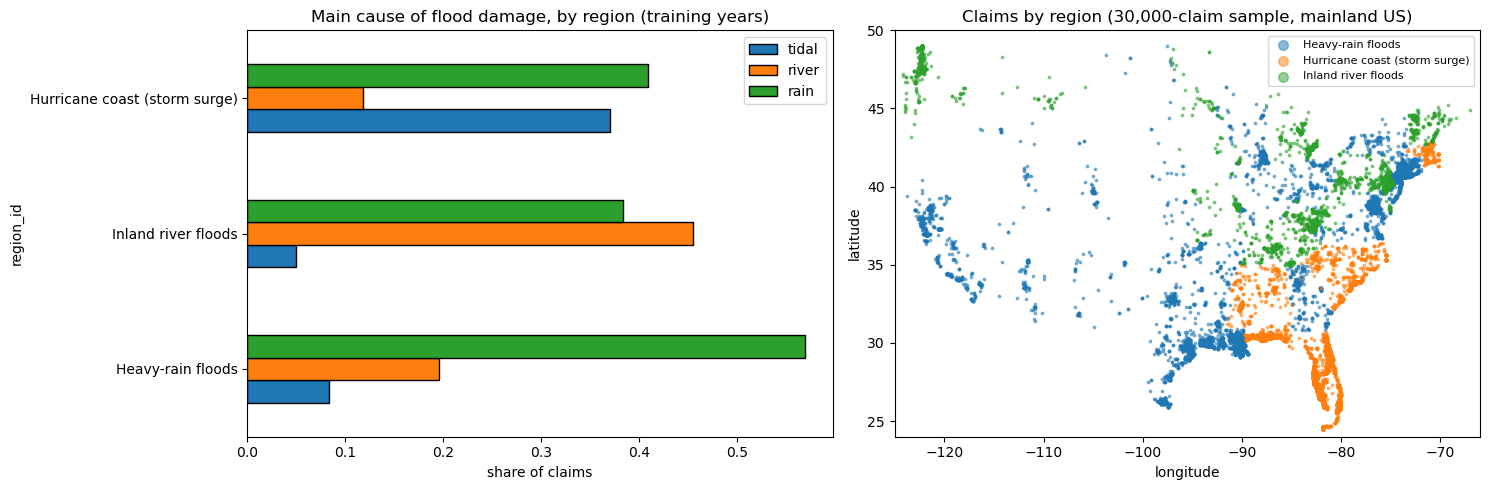

In [6]:
# Charts: what kind of flood each region has, and where the regions are
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
rp = region_profile.rename(index=NAMES)
rp[['tidal', 'river', 'rain']].plot.barh(ax=ax[0], edgecolor='black')
ax[0].set_title('Main cause of flood damage, by region (training years)'); ax[0].set_xlabel('share of claims')

pts = work[train].sample(30000, random_state=SEED)
for name in sorted(pts['region'].dropna().unique()):
    p = pts[pts['region'] == name]
    ax[1].scatter(p['longitude'], p['latitude'], s=3, alpha=0.5, label=name)
ax[1].set_xlim(-125, -66); ax[1].set_ylim(24, 50)
ax[1].set_title('Claims by region (30,000-claim sample, mainland US)'); ax[1].set_xlabel('longitude'); ax[1].set_ylabel('latitude')
ax[1].legend(markerscale=4, fontsize=8)
plt.tight_layout(); plt.show()

**The three regions**

| Region | Train claims | Main flood type | Buildings | Main states |
|---|---|---|---|---|
| **Hurricane coast (storm surge)** | 85,657 | 37% storm surge | almost no basements (1%) | FL, AL, MS, NC, SC (+ HI, MA, RI, territories) |
| **Heavy-rain floods** | 61,250 | 57% heavy rain; 38% outside the mapped flood zone | 20% basements | LA, TX, NJ, NY, CA, GA, VA, ... |
| **Inland river floods** | 14,634 | 45% river overflow | 28% basements | PA, KY, TN, WV, MO, MI, WA, ... |

- With 4 or more regions, one region has only about 1,400 claims, too few for a model. So we use **3 regions**.
- The silhouette for 3 regions is 0.24: the regions are clear, but some states sit between two of them.
- **The grouping follows the floods of 2020-2023, not only the map.** For example, Louisiana and Texas are in "heavy rain",
  because most of their claims in these years were rain floods (Hurricane Ida flooded mostly by rainfall).
- Most test claims are on the hurricane coast (87,055), because Helene and Milton hit Florida in 2024.

---
# Section 2: Local (County) Features

A national model sees each claim alone. A local feature tells the model something about **the place**.
We make five county features, **from the training years only** (2020-2023), so the test years stay unseen:

| Feature | Meaning | Type |
|---|---|---|
| `county_past_claims` | how many claims the county had | exposure |
| `county_tidal_share` | share of the county's past claims caused by storm surge | exposure |
| `county_v_zone_share` | share of the county's past claims in the coastal V zone | exposure |
| `county_past_payment` | average log payment in the county in the past | past outcome |
| `county_past_severe_share` | share of high-severity claims in the county in the past | past outcome |

Counties with few past claims are pulled toward the national average ("smoothing"), so one big claim cannot dominate.
Counties with no past claims get the national average.

In [7]:
paid_t = t[t['is_paid'] == 1]
K_SMOOTH = 30
glob_pay = paid_t['log_paid_building'].mean()
glob_sev = t['high_severity'].mean()
n_pay = paid_t.groupby('countyCode').size(); m_pay = paid_t.groupby('countyCode')['log_paid_building'].mean()
n_sev = t.groupby('countyCode')['high_severity'].count(); m_sev = t.groupby('countyCode')['high_severity'].mean()
cg = t.groupby('countyCode')
county = pd.DataFrame({
    'county_past_claims': cg.size(),
    'county_tidal_share': cg['causeOfDamage'].apply(lambda s: (s == '1').mean()),
    'county_v_zone_share': cg['flood_zone_family'].apply(lambda s: (s == 'V').mean()),
    'county_past_payment': (m_pay * n_pay + glob_pay * K_SMOOTH) / (n_pay + K_SMOOTH),
    'county_past_severe_share': (m_sev * n_sev + glob_sev * K_SMOOTH) / (n_sev + K_SMOOTH),
})
LOCAL = work[['countyCode']].join(county, on='countyCode').drop(columns='countyCode')
LOCAL['county_past_payment'] = LOCAL['county_past_payment'].fillna(glob_pay)
LOCAL['county_past_severe_share'] = LOCAL['county_past_severe_share'].fillna(glob_sev)
LOCAL = LOCAL.fillna(0)

new_counties = test & ~work['countyCode'].isin(county.index)
print(f'Counties with past claims: {len(county):,}')
print(f'Test claims in a county with NO past claims: {new_counties.sum():,} ({new_counties.sum() / test.sum():.1%} of test)')
print()
print('Test claims per region, and share in counties with no past claims:')
print(work[test].assign(new=new_counties[test]).groupby('region').agg(test_claims=('new', 'size'), new_county_share=('new', 'mean')).round(3))

Counties with past claims: 1,982
Test claims in a county with NO past claims: 984 (0.9% of test)

Test claims per region, and share in counties with no past claims:
                               test_claims  new_county_share
region                                                      
Heavy-rain floods                    20095             0.019
Hurricane coast (storm surge)        87055             0.001
Inland river floods                   7878             0.065


---
# Section 3: RQ1 by Region: How much will FEMA pay?

Four models, all **random forests** with the same settings, scored on each region's 2024-2025 claims (R²):

1. **National:** trained on all regions, RQ1 features
2. **National + local:** the same, plus the five county features
3. **Regional:** trained only on that region's claims
4. **Regional + local:** regional, plus the county features

In [8]:
def forest_reg():
    return RandomForestRegressor(n_estimators=100, min_samples_leaf=20, n_jobs=-1, random_state=SEED)

paid = work['is_paid'] == 1
y1 = work['log_paid_building']
X1 = X_all[FL['RQ1']]
X1L = pd.concat([X1, LOCAL], axis=1)

nat = forest_reg().fit(X1[train & paid], y1[train & paid])
natL = forest_reg().fit(X1L[train & paid], y1[train & paid])
rows = []
for name in sorted(work['region'].dropna().unique()):
    reg = work['region'] == name
    a, b = train & paid & reg, test & paid & reg
    regm = forest_reg().fit(X1[a], y1[a])
    regL = forest_reg().fit(X1L[a], y1[a])
    rows.append({'region': name, 'train claims': int(a.sum()), 'test claims': int(b.sum()),
                 'national': r2_score(y1[b], nat.predict(X1[b])),
                 'national + local': r2_score(y1[b], natL.predict(X1L[b])),
                 'regional': r2_score(y1[b], regm.predict(X1[b])),
                 'regional + local': r2_score(y1[b], regL.predict(X1L[b]))})
rq1_reg = pd.DataFrame(rows).set_index('region')
rq1_reg.style.format({'national': '{:.3f}', 'national + local': '{:.3f}', 'regional': '{:.3f}', 'regional + local': '{:.3f}',
                      'train claims': '{:,}', 'test claims': '{:,}'})

,train claims,test claims,national,national + local,regional,regional + local
region,,,,,,
Heavy-rain floods,"43,641","14,860",0.111,0.033,0.071,0.014
Hurricane coast (storm surge),"64,362","71,813",0.325,0.317,0.113,0.306
Inland river floods,"11,743","6,512",0.131,-0.033,0.153,-0.007


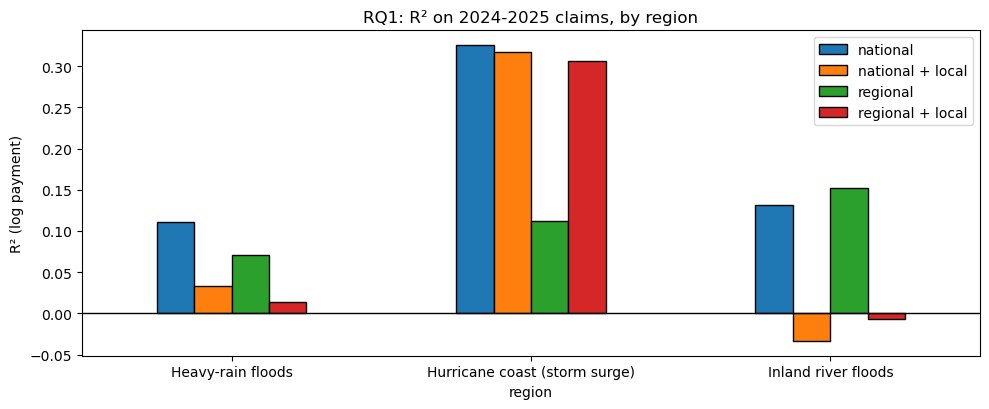

In [9]:
ax = rq1_reg[['national', 'national + local', 'regional', 'regional + local']].plot.bar(figsize=(10, 4.2), edgecolor='black', rot=0)
ax.axhline(0, color='black', lw=1)
ax.set_title('RQ1: R² on 2024-2025 claims, by region'); ax.set_ylabel('R² (log payment)')
plt.tight_layout(); plt.show()

**Why is the regional model so much worse on the hurricane coast?** We check the coast's test claims storm by storm.

In [10]:
coast = 'Hurricane coast (storm surge)'
a, b = train & paid & (work['region'] == coast), test & paid & (work['region'] == coast)
coast_model = forest_reg().fit(X1[a], y1[a])
d = work[b].assign(national=nat.predict(X1[b]), regional=coast_model.predict(X1[b]))
rows = []
for ev, gr in d.groupby('floodEvent'):
    if len(gr) >= 2000:
        rows.append({'storm': ev, 'claims': len(gr), 'R2 national': r2_score(gr['log_paid_building'], gr['national']),
                     'R2 regional': r2_score(gr['log_paid_building'], gr['regional']),
                     'true mean log pay': gr['log_paid_building'].mean(), 'national mean pred': gr['national'].mean(),
                     'regional mean pred': gr['regional'].mean()})
print(pd.DataFrame(rows).round(3).to_string(index=False))
print()
print('Cause of damage, coast, train years:', work.loc[a, 'causeOfDamage'].value_counts(normalize=True).head(3).round(2).to_dict())
print('Cause of damage, coast, test years :', work.loc[b, 'causeOfDamage'].value_counts(normalize=True).head(3).round(2).to_dict())

           storm  claims  R2 national  R2 regional  true mean log pay  national mean pred  regional mean pred
Hurricane Helene   49636        0.376        0.072             11.015              10.524              10.242
Hurricane Milton   16249        0.062       -0.002             10.348              10.335              10.415
  no_named_event    2142        0.099        0.094              9.749               9.526               9.615

Cause of damage, coast, train years: {'4': 0.42, '1': 0.4, '2': 0.14}
Cause of damage, coast, test years : {'4': 0.45, '1': 0.45, '2': 0.08}


The gap comes almost only from **Hurricane Helene**. Its claims were not a different kind of flood
(the cause mix is about the same as in the training years). But the regional model predicted
lower payments for Helene than the national model did, and Helene's payments were high.
The national model, trained on more different floods, generalised better to this storm.
We could not find one simple reason, so we report it as an observation.

## 3.1 A fair check: what if the test storms were already known?

On 2024-2025 the model meets **new storms in new places**. Local features describe **past** storms.
To see whether local features *can* help at all, we also test with a random 70/30 split inside each region
(all years mixed, so the same storms are in train and test). This is the setup used in many published papers.

In [11]:
rows = []
for name in sorted(work['region'].dropna().unique()):
    idx = work.index[paid & (work['region'] == name)]
    a, b = train_test_split(idx, test_size=0.3, random_state=SEED)
    m0 = forest_reg().fit(X1.loc[a], y1[a]); mL = forest_reg().fit(X1L.loc[a], y1[a])
    rows.append({'region': name, 'regional': r2_score(y1[b], m0.predict(X1.loc[b])),
                 'regional + local': r2_score(y1[b], mL.predict(X1L.loc[b]))})
rq1_random = pd.DataFrame(rows).set_index('region')
rq1_random['gain from local'] = rq1_random['regional + local'] - rq1_random['regional']
rq1_random.round(3)

,regional,regional + local,gain from local
region,,,
Heavy-rain floods,0.328,0.338,0.011
Hurricane coast (storm surge),0.530,0.532,0.002
Inland river floods,0.313,0.329,0.016


## 3.2 Answer to RQ1 by region

| Region | National | National + local | Regional | Regional + local |
|---|---|---|---|---|
| Heavy-rain floods | **0.111** | 0.033 | 0.071 | 0.014 |
| Hurricane coast | **0.325** | 0.317 | 0.113 | 0.306 |
| Inland river floods | 0.131 | -0.033 | **0.153** | -0.007 |

**Answer in plain words.**
- **Regional models did not beat the national model**, except a small gain for inland river floods (0.153 vs 0.131).
- **Local county features did not help the best model in any region.** Added to the national model, they lowered R² everywhere
  (most in the river region, 0.131 → -0.033). They describe *past* storms in each county, and the new storms hit with a different strength:
  "this county used to have small claims" was no longer true.
- **One exception:** on the hurricane coast, local features rescued the regional model (0.113 → 0.306), but it still stayed
  just below the national model (0.325).
- When the same storms are in training and testing (random split, Section 3.1), local features help only a little
  (+0.002 to +0.016 R²). So even in the easy case, county history adds little to what the building features already say.
- **The biggest difference is between regions, not between models.** Payments on the hurricane coast are much easier to
  predict (R² 0.33) than in the heavy-rain (0.11) or river regions (0.13). Rain and river floods depend on local rain and river levels
  that are not in our data.

---
# Section 4: RQ2 by Region: Is the claim high severity?

The same four models, now **random forest classifiers** with `class_weight='balanced'`.
We report **ROC-AUC** (how well the model ranks severe claims first; 0.5 = random) and **F1**.

In [12]:
def forest_cls():
    return RandomForestClassifier(n_estimators=100, min_samples_leaf=20, class_weight='balanced', n_jobs=-1, random_state=SEED)

lab = work['high_severity'].notna()
y2 = work['high_severity'].fillna(0).astype(int)
X2 = X_all[FL['RQ2']]
X2L = pd.concat([X2, LOCAL], axis=1)

nat2 = forest_cls().fit(X2[train & lab], y2[train & lab])
nat2L = forest_cls().fit(X2L[train & lab], y2[train & lab])
rows = []
for name in sorted(work['region'].dropna().unique()):
    reg = work['region'] == name
    a, b = train & lab & reg, test & lab & reg
    m = forest_cls().fit(X2[a], y2[a]); mL = forest_cls().fit(X2L[a], y2[a])
    row = {'region': name, 'severe share train': y2[a].mean(), 'severe share test': y2[b].mean()}
    for label, model, X in [('national', nat2, X2), ('national + local', nat2L, X2L), ('regional', m, X2), ('regional + local', mL, X2L)]:
        row[f'AUC {label}'] = roc_auc_score(y2[b], model.predict_proba(X[b])[:, 1])
        row[f'F1 {label}'] = f1_score(y2[b], model.predict(X[b]))
    rows.append(row)
rq2_reg = pd.DataFrame(rows).set_index('region')
rq2_reg.round(3)

,severe share train,severe share test,AUC national,F1 national,AUC national + local,F1 national + local,AUC regional,F1 regional,AUC regional + local,F1 regional + local
region,,,,,,,,,,
Heavy-rain floods,0.075,0.091,0.762,0.294,0.770,0.255,0.760,0.326,0.754,0.279
Hurricane coast (storm surge),0.206,0.333,0.764,0.543,0.745,0.467,0.759,0.300,0.751,0.373
Inland river floods,0.084,0.116,0.796,0.325,0.741,0.326,0.792,0.398,0.733,0.331


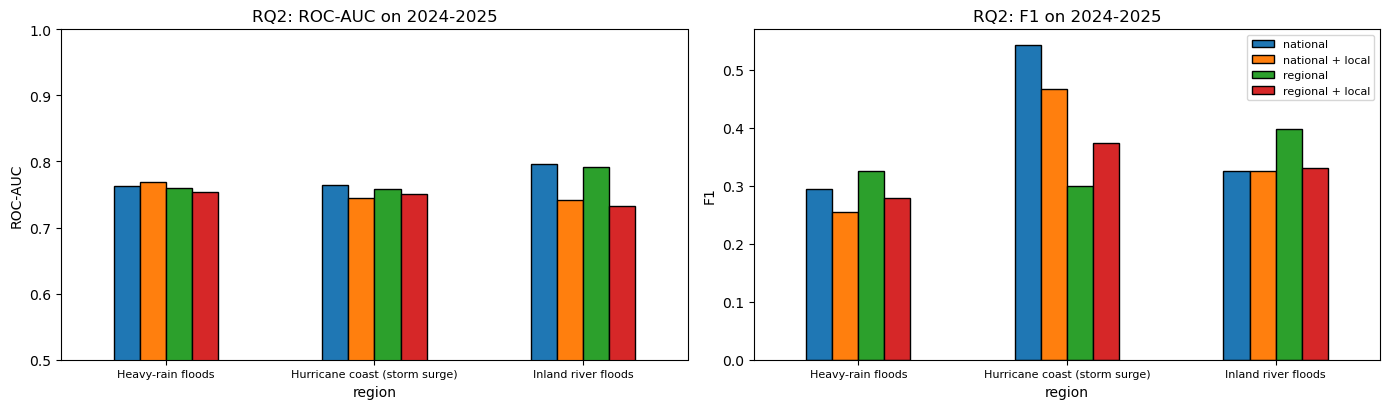

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
rq2_reg[['AUC national', 'AUC national + local', 'AUC regional', 'AUC regional + local']].plot.bar(ax=ax[0], edgecolor='black', rot=0, legend=False)
ax[0].set_ylim(0.5, 1); ax[0].set_title('RQ2: ROC-AUC on 2024-2025'); ax[0].set_ylabel('ROC-AUC')
rq2_reg[['F1 national', 'F1 national + local', 'F1 regional', 'F1 regional + local']].plot.bar(ax=ax[1], edgecolor='black', rot=0)
ax[1].set_title('RQ2: F1 on 2024-2025'); ax[1].set_ylabel('F1')
ax[1].legend(['national', 'national + local', 'regional', 'regional + local'], fontsize=8)
for a in ax: a.tick_params(axis='x', labelsize=8)
plt.tight_layout(); plt.show()

## 4.1 Answer to RQ2 by region

| Region | Severe share train → test | AUC national | AUC regional | F1 national | F1 regional |
|---|---|---|---|---|---|
| Heavy-rain floods | 7.5% → 9.1% | 0.762 | 0.760 | 0.294 | **0.326** |
| Hurricane coast | 20.6% → 33.3% | 0.764 | 0.759 | **0.543** | 0.300 |
| Inland river floods | 8.4% → 11.6% | **0.796** | 0.792 | 0.325 | **0.398** |

**Answer in plain words.**
- **Ranking severe claims first (ROC-AUC) is equally good** with national and regional models, about 0.76-0.80 in every region.
  Local features lowered the AUC slightly.
- **Regional models give a better F1 in the two smaller regions** (rain 0.33 vs 0.29, river 0.40 vs 0.33).
  There, severe claims are rare (about 8-9%), and a regional model learns that lower rate.
- **On the hurricane coast the regional model is much worse** (F1 0.30 vs 0.54): severe claims jumped from 21% to 33% in 2024,
  and the regional model, which only knew the coast's earlier storms, flagged too few of them.

---
# Section 5: RQ3 by Region: Which building profiles exist, and which are most at risk?

Inside each region we cluster claims on the same building features as before
(flood zone, foundation, age, floors, occupancy, CRS class, coverage), with the same coding fix:
old occupancy codes are translated and claims with no recorded foundation are left out.
We pick k with the highest silhouette between 3 and 8. Damage is **not** used to form the clusters,
only afterwards to see which profile is most at risk.

In [14]:
OLD_TO_NEW = {1: 11, 2: 12, 3: 13, 4: 18, 6: 18}
FOUNDATION = {'1': 'slab', '2': 'basement', '3': 'crawlspace', '4': 'elevated open (piles/piers)',
              '5': 'elevated enclosed (piles)', '6': 'elevated enclosed (walls)'}
OCCUPANCY = {11: 'single family', 12: '2-4 units', 13: '5+ units', 14: 'mobile home', 15: 'condo building',
             16: 'unit in building', 17: 'non-res. mobile', 18: 'non-residential', 19: 'non-res. unit'}
NOM3 = [c for c in FL['RQ3'] if c in FL['NOMINAL_FEATURES']]

def describe(d):
    fnd = FOUNDATION.get(d['foundationType'].value_counts().index[0], '?')
    occ = OCCUPANCY.get(d['occupancyType'].value_counts().index[0], '?')
    return f"{fnd}, {occ}, ~{d['building_age'].median():.0f} yrs, zone {d['flood_zone_family'].value_counts().index[0]}"

rq3_rows, rq3_detail = [], {}
for name in sorted(work['region'].dropna().unique()):
    w3 = work[(work['region'] == name) & (work['foundationType'] != '0')].copy()
    w3['occupancyType'] = w3['occupancyType'].replace(OLD_TO_NEW)
    s3 = w3.sample(min(15000, len(w3)), random_state=SEED)
    X3 = pd.get_dummies(s3[FL['RQ3']], columns=NOM3, dtype=int)
    X3['totalBuildingInsuranceCoverage'] = np.log1p(X3['totalBuildingInsuranceCoverage'])
    Zr = StandardScaler().fit_transform(X3)
    sils = {k: silhouette_score(Zr, KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Zr).labels_,
                                sample_size=5000, random_state=SEED) for k in range(3, 9)}
    k_best = max(sils, key=sils.get)
    s3['cluster'] = KMeans(n_clusters=k_best, n_init=10, random_state=SEED).fit(Zr).labels_
    summary = s3.groupby('cluster')[s3.columns.drop('cluster')].apply(lambda d: pd.Series({
        'claims': len(d), 'profile': describe(d), 'high severity': d['high_severity'].mean(),
        'median payment': d.loc[d['amountPaidOnBuildingClaim'] > 0, 'amountPaidOnBuildingClaim'].median()}))
    summary = summary.sort_values('high severity', ascending=False)
    rq3_detail[name] = summary
    top, low = summary.iloc[0], summary.iloc[-1]
    rq3_rows.append({'region': name, 'k': k_best, 'silhouette': round(sils[k_best], 3),
                     'most at risk': top['profile'], 'severe share (most)': round(top['high severity'], 3),
                     'least at risk': low['profile'], 'severe share (least)': round(low['high severity'], 3)})
rq3_reg = pd.DataFrame(rq3_rows).set_index('region')
rq3_reg

,k,silhouette,most at risk,severe share (most),least at risk,severe share (least)
region,,,,,,
Heavy-rain floods,6,0.155,"slab, non-residential, ~47 yrs, zone AE",0.251,"slab, unit in building, ~39 yrs, zone X",0.000
Hurricane coast (storm surge),3,0.322,"slab, single family, ~49 yrs, zone AE",0.305,"elevated open (piles/piers), mobile home, ~46 ...",0.046
Inland river floods,3,0.236,"slab, non-residential, ~49 yrs, zone AE",0.240,"elevated open (piles/piers), mobile home, ~27 ...",0.025


In [15]:
for name, summary in rq3_detail.items():
    print('=' * 100)
    print(name)
    print(summary.assign(**{'high severity': summary['high severity'].round(3),
                            'median payment': summary['median payment'].round(0)}).to_string())

Heavy-rain floods
         claims                                                     profile  high severity  median payment
cluster                                                                                                   
1          1245                     slab, non-residential, ~47 yrs, zone AE          0.251         50000.0
0          1789                       basement, 2-4 units, ~57 yrs, zone AE          0.102         22751.0
4          7686                       slab, single family, ~47 yrs, zone AE          0.072         25058.0
3          3934                   basement, single family, ~52 yrs, zone AE          0.055         15798.0
5           192  elevated open (piles/piers), mobile home, ~20 yrs, zone AE          0.041          8986.0
2           154                     slab, unit in building, ~39 yrs, zone X          0.000         14823.0
Hurricane coast (storm surge)
         claims                                                     profile  high severity  medi

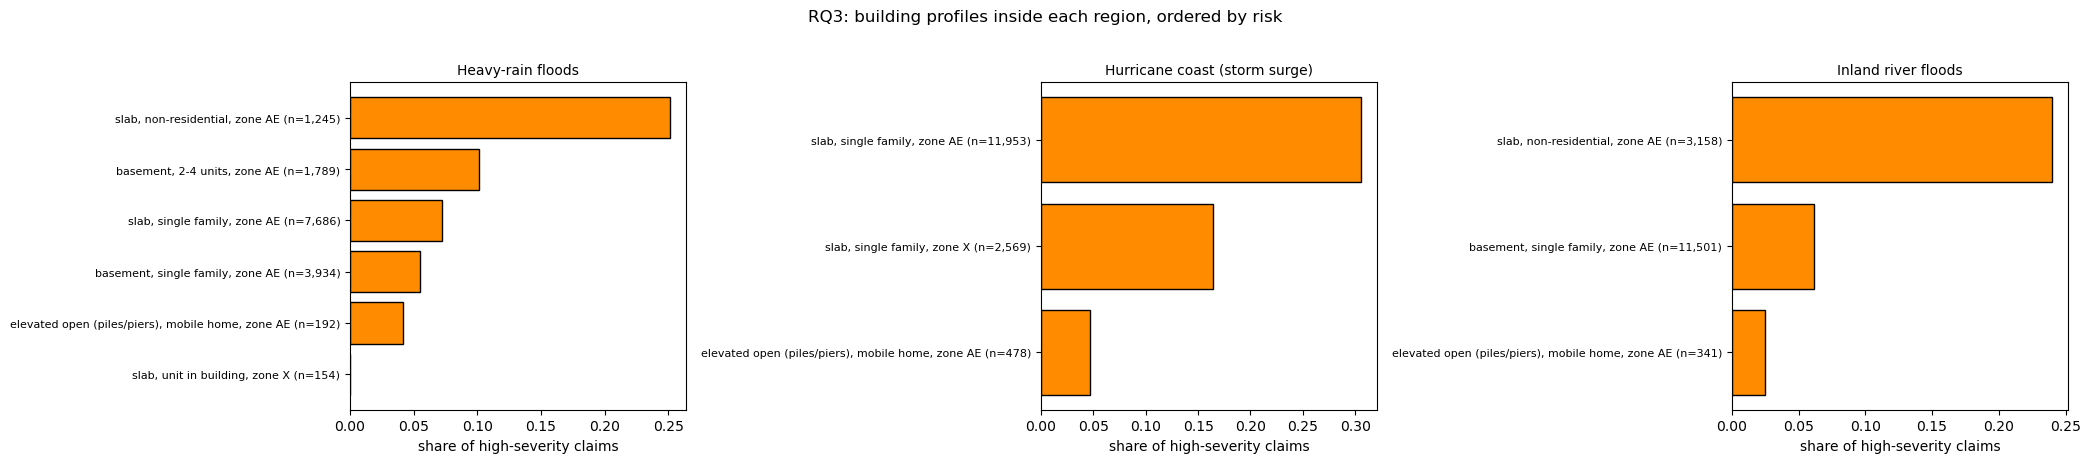

In [16]:
fig, axes = plt.subplots(1, len(rq3_detail), figsize=(7 * len(rq3_detail), 4.5))
for ax, (name, summary) in zip(np.atleast_1d(axes), rq3_detail.items()):
    labels = [f"{p.split(',')[0]}, {p.split(',')[1].strip()}, {p.split(',')[3].strip()} (n={n:,})"
              for p, n in zip(summary['profile'], summary['claims'])]
    ax.barh(labels[::-1], summary['high severity'].values[::-1], color='darkorange', edgecolor='black')
    ax.set_title(name, fontsize=10); ax.set_xlabel('share of high-severity claims')
    ax.tick_params(axis='y', labelsize=8)
plt.suptitle('RQ3: building profiles inside each region, ordered by risk', y=1.02)
plt.tight_layout(); plt.show()

## 5.1 Answer to RQ3 by region

| Region | Groups (k) | Silhouette | Most at risk | Severe | Least at risk | Severe |
|---|---|---|---|---|---|---|
| Hurricane coast | 3 | 0.32 | slab, single family, zone AE | **30.5%** | elevated / mobile home | 4.6% |
| Heavy-rain floods | 6 | 0.16 | slab, non-residential, zone AE | **25.1%** | units in a building, zone X | 0.0% |
| Inland river floods | 3 | 0.24 | slab, non-residential, zone AE | **24.0%** | elevated / mobile home | 2.5% |

**Answer in plain words.**
- **One pattern holds in every region: buildings on a slab at ground level are the most at risk, elevated buildings the least.**
- **But who is at risk differs by region:**
  - On the **hurricane coast**, the risk group is **ordinary single-family slab homes** in the AE zone (30% severe, median payment about $75,000).
  - In the **rain and river regions**, the risk group is **non-residential slab buildings** (shops, offices; about 24-25% severe).
    The typical home there has a **basement**, and basement homes are a large group but rarely reach the high-severity level (5-6%).
- So a national answer ("slab homes are most at risk") hides that inland, the biggest severe losses are **businesses**, not homes.
- The heavy-rain region has the weakest groups (silhouette 0.16): its buildings are very mixed.

---
# Section 6: Summary

## What we learned

1. **States can be grouped by flood type** into three regions: the hurricane coast (storm surge), heavy-rain floods and inland river floods.
2. **Regional models and county features did not make the payment prediction (RQ1) better on new storms.**
   The national model was best in two of three regions; the regional model won only for river floods (0.153 vs 0.131).
   County history describes past storms and usually misled the models when new storms came.
3. **Accuracy depends on the region.** Hurricane-coast payments are about three times easier to explain (R² 0.33) than rain or river floods (0.11-0.13).
4. **For RQ2, regional models helped F1 where severe claims are rare** (rain, river), and hurt where severe claims suddenly increased (coast).
5. **For RQ3, the regional view adds a real insight:** on the coast, single-family slab homes are the risk group;
   inland, it is non-residential slab buildings, while the many basement homes rarely become severe.

## What this does not show
- **Only 3 regions.** More regions would give more local detail, but too few claims per region.
- **Very uneven test data.** 76% of test claims are hurricane-coast claims from Helene and Milton, so coast results weigh most.
- **The high-severity cut-off is national.** In cheaper regions fewer claims cross it; a regional cut-off would change RQ2 and RQ3 there.
- **The regions follow the floods of 2020-2023.** A different period could move some states (for example Louisiana) to another region.

## What could really help next
The missing information is **how strong the flood was at each place**: rainfall, river height or storm-surge height.
These come from other public sources (for example NOAA rainfall data or USGS river gauges) and can be joined by date and location.
Our results suggest this, not more county history, is the local information that matters.